# Combine forced-choice blocks and individual items

Use one model for 80 respondents who answered ranked forced-choice triplets,
ordinal ratings and a binary item. Assign each forced-choice block a ranking
law and then decide whether the individual items measure the same traits.

## Combine response laws on a common trait scale

Let $\boldsymbol\theta_p$ be the vector of trait scores for person $p$.
For each observed response, the model uses the probability assigned by
the law selected for that block or item:

$$
L_p(\boldsymbol\theta_p)
= \prod_{b\in\mathcal B_p} P_b(R_{pb}\mid\boldsymbol\theta_p)
  \prod_{j\in\mathcal J_p} P_j(Y_{pj}\mid\boldsymbol\theta_p).
$$

$\mathcal B_p$ is the set of blocks with observed responses $R_{pb}$ and
$\mathcal J_p$ the set of items with observed ratings $Y_{pj}$.
$P_b$ and $P_j$ condition on the corresponding statement or item parameters,
which the notation leaves implicit. Each factor uses the trait scores
named by that part of the design.

Blocks B1–B3 use [MGPPM](mgppm_workflow.ipynb#model-the-ranking-patterns).
For $A>B>C$, the order gets weight $\exp(2u_{pA}+u_{pB})$, where $u_{pj}$
denotes statement utility. Its probability divides that weight by the
total for all six orders. Block B4 uses [2PLM-RANK](two_pl_rank_workflow.ipynb#define-the-endorsement-model):
the probability is the chance of selecting $A$ first times the chance of
selecting $B$ from $\{B,C\}$.

Items I1–I3 use [GPCM](binary_ordinal_workflow.ipynb#generalized-partial-credit-model-gpcm)
for five ordered categories. Item I4 uses
[2PL](binary_ordinal_workflow.ipynb#dichotomous-irt) for two categories.
In the shared-trait fit, both response channels use the same agency score
$\theta_{p,\mathrm{agency}}$. In the separate-trait fit, the item factors
use a distinct self-report score. The scoring of an individual response
under its measurement law is the same in both fits.

## Read the two response tables

The bundled simulation has four triplets and four items per person. The FC
design specifies the statements and their traits. Negative keying changes the
loading direction in the model.
The loader's model mapping supplies names for the two input channels.
The block and item declarations below set the models used for fitting.

In [1]:
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

study = fc.load_example("mixed_measurement", model={"fc": "MGPPM", "items": "GPCM"})
loaded_fc, loaded_items = study.data
loaded_fc.design.head(3)

,block_id,position,statement_id,trait,keying
0,B1,1,A,agency,1
1,B1,2,B,stability,1
2,B1,3,C,agency,-1


An FC row gives a ranking of statement positions. The first row's [3, 1, 2]
places statement 3 ahead of statement 1, followed by statement 2.

In [2]:
fc_df = loaded_fc.responses.frame
fc_df.head(3)

,person_id,block_id,response
0,P001,B1,"[3, 1, 2]"
1,P002,B1,"[2, 1, 3]"
2,P003,B1,"[1, 2, 3]"


An item row gives one category for a person and item. Matching person IDs
identify the same respondents across the two tables.

In [3]:
item_df = loaded_items.responses.frame
item_df.head(3)

,person_id,item_id,response
0,P001,I1,1
1,P002,I1,3
2,P003,I1,2


## Assign response laws

Use MGPPM for the first three blocks and override B4 with TwoPLRank.
The rank format stays the same for all four blocks. Each reference statement
sets one intercept to zero. For the items, use GPCM with five categories by
default and override I4 with binary 2PL and two categories.

In [4]:
fc_spec = """
[traits]
agency ~ A C E G I K
stability ~ B D F H J L
sign - ~ C F I L

[blocks]
B1 ~ A B C
B2 ~ D E F
B3 ~ G H I
B4 ~ J K L
"""


def joint_model(item_design):
    model = fc.Model()
    model.add_fc(
        fc_spec,
        fc_df,
        format="block_long",
        response_format="rank",
        model=fc.MGPPM(reference_statements=("A", "D", "G")),
        blocks={"B4": {"model": fc.TwoPLRank(reference_statements=("J",))}},
    )
    model.add_items(
        item_design,
        item_df,
        format="item_long",
        model="GPCM",
        categories=(0, 1, 2, 3, 4),
        items={
            "I4": {
                "model": fc.DichotomousIRT(kind="2PL"),
                "categories": (0, 1),
            }
        },
    )
    return model.prepare()

## Compare the two trait assignments

The two summaries list the same measurement models and response counts. The shared assignment has two traits; the separate assignment adds a third trait for the individual items.

In [5]:
shared_item_spec = """
[traits]
agency ~ I1 I2 I3 I4
"""


shared_model = joint_model(shared_item_spec)
print(shared_model.summary())

Models: MGPPM, TwoPLRank, GPCM, DichotomousIRT
80 people, 2 traits, 4 blocks, 4 items, 12 FC statements
Observations: 320 block events; 320 item responses
Measurements:
  MGPPM / rank: 3 blocks, size=3, categories=6
  TwoPLRank / rank: 1 block, size=3, categories=6
  GPCM: 3 items, categories=5
  DichotomousIRT: 1 item, link=logit
Population:
  theta ~ MvNormal(mu=0, cov=R)
  R [2 x 2] ~ LKJCorr(n=2, eta=1)
Priors:
  MGPPM:
    loading [9] ~ LogNormal(mu=0, sigma=0.5)
    statement_intercept [6] ~ Normal(mu=0, sigma=2)
  TwoPLRank:
    loading [3] ~ LogNormal(mu=0, sigma=0.5)
    statement_intercept [2] ~ Normal(mu=0, sigma=2)
  GPCM:
    loading [3] ~ LogNormal(mu=0.25, sigma=0.5)
    category_intercept [12] ~ Normal(mu=0, sigma=1)
  DichotomousIRT:
    loading [1] ~ LogNormal(mu=0.25, sigma=0.5)
    item_intercept [1] ~ Normal(mu=0, sigma=1)
Constraints:
  MGPPM:
    statement_intercept: fixed=0 [3 fixed]
  TwoPLRank:
    statement_intercept: fixed=0 [1 fixed]
  DichotomousIRT:
    l

In the second model, the item channel gets its own self_report trait.
The FC responses still measure agency and stability. The separate traits
can correlate, and both fits use the same respondents and responses.

In [6]:
separate_item_spec = """
[traits]
self_report ~ I1 I2 I3 I4
"""


separate_model = joint_model(separate_item_spec)
print(separate_model.summary())

Models: MGPPM, TwoPLRank, GPCM, DichotomousIRT
80 people, 3 traits, 4 blocks, 4 items, 12 FC statements
Observations: 320 block events; 320 item responses
Measurements:
  MGPPM / rank: 3 blocks, size=3, categories=6
  TwoPLRank / rank: 1 block, size=3, categories=6
  GPCM: 3 items, categories=5
  DichotomousIRT: 1 item, link=logit
Population:
  theta ~ MvNormal(mu=0, cov=R)
  R [3 x 3] ~ LKJCorr(n=3, eta=1)
Priors:
  MGPPM:
    loading [9] ~ LogNormal(mu=0, sigma=0.5)
    statement_intercept [6] ~ Normal(mu=0, sigma=2)
  TwoPLRank:
    loading [3] ~ LogNormal(mu=0, sigma=0.5)
    statement_intercept [2] ~ Normal(mu=0, sigma=2)
  GPCM:
    loading [3] ~ LogNormal(mu=0.25, sigma=0.5)
    category_intercept [12] ~ Normal(mu=0, sigma=1)
  DichotomousIRT:
    loading [1] ~ LogNormal(mu=0.25, sigma=0.5)
    item_intercept [1] ~ Normal(mu=0, sigma=1)
Constraints:
  MGPPM:
    statement_intercept: fixed=0 [3 fixed]
  TwoPLRank:
    statement_intercept: fixed=0 [1 fixed]
  DichotomousIRT:
    l

## Fit both models

In [7]:
shared_model.fit(draws=3000, tune=1500, chains=4, random_seed=20261118);

In [8]:
separate_model.fit(draws=3000, tune=1500, chains=4, random_seed=20261119);

## Diagnose the chains

Check both fits before comparing their score estimates. R-hat summarizes agreement across chains.

In [9]:
import arviz as az
import numpy as np

for label, fitted in [
    ("Shared agency", shared_model),
    ("Separate self-report", separate_model),
]:
    posterior = fitted.idata.posterior.to_dataset().reset_coords(drop=True)
    with np.errstate(invalid="ignore", divide="ignore"):
        r_hat = az.rhat(posterior).max().to_array().max().item()
        bulk = az.ess(posterior, method="bulk").min().to_array().min().item()
    divergences = int(fitted.idata.sample_stats.diverging.sum())
    print(f"{label}: max R-hat {r_hat:.3f}, min bulk ESS {bulk:.0f}, divergences {divergences}")

Shared agency: max R-hat 1.001, min bulk ESS 4584, divergences 0


Separate self-report: max R-hat 1.006, min bulk ESS 1833, divergences 0


The rank panels compare the chains for respondent P001's agency score, a
trait estimated in both configurations. The rank-test p-values for that
score are 0.67 and 0.75.

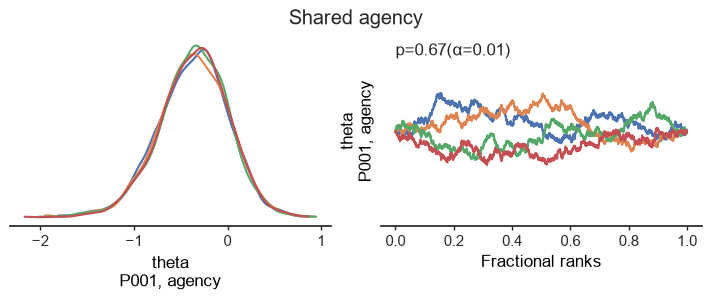

In [10]:
import arviz_plots as azp
import matplotlib.pyplot as plt


def rank_plot(fitted, title):
    azp.plot_rank_dist(
        fitted.idata,
        var_names=["theta"],
        coords={"person": ["P001"], "trait": ["agency"]},
        backend="matplotlib",
        compact=False,
        figure_kwargs={"figsize": (7, 2.9), "layout": "constrained"},
    )
    plt.gcf().suptitle(title)
    plt.show()


rank_plot(shared_model, "Shared agency")

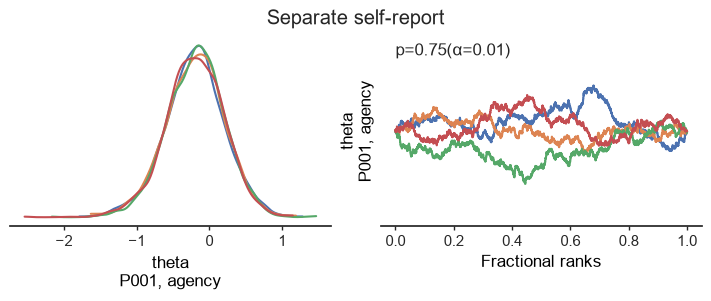

In [11]:
rank_plot(separate_model, "Separate self-report")

## Compare uncertainty in respondents' agency scores

The table shows which trait the shared model assigns to one FC block
and two individual items.

In [12]:
shared_model.coef(
    blocks=["B1"],
    items=["I1", "I4"],
    var_names="loading",
    kind="stats",
    round_to=2,
)

mean    sd  hdi95_lb  hdi95_ub  \
channel unit statement trait     parameter                                   
fc      B1   A         agency    loading    0.86  0.25      0.38      1.36   
             B         stability loading    0.90  0.26      0.42      1.40   
             C         agency    loading    1.07  0.31      0.51      1.69   
items   I1   nan       agency    loading    0.79  0.18      0.46      1.15   
        I4   nan       agency    loading    1.02  0.29      0.49      1.61   

                                           model_response_format  
channel unit statement trait     parameter                        
fc      B1   A         agency    loading            MGPPM / rank  
             B         stability loading            MGPPM / rank  
             C         agency    loading            MGPPM / rank  
items   I1   nan       agency    loading                    GPCM  
        I4   nan       agency    loading          DichotomousIRT

Compare the posterior SD of agency for the same 80 respondents in each
fit. In the shared fit, both forced-choice blocks and individual items
measure agency. In the separate fit, only the forced-choice blocks
measure agency.

Each half violin shows the distribution of SDs. The box spans the middle
50%, the line inside marks the median, and each dot represents one
respondent.

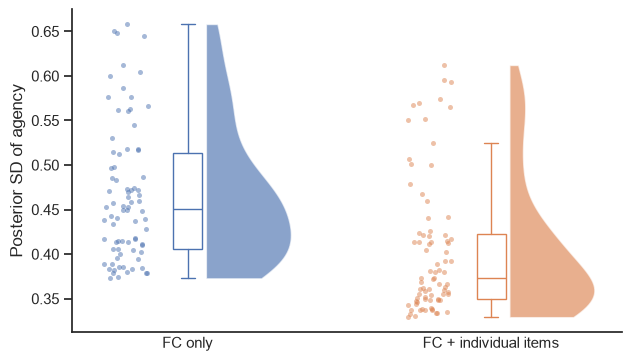

In [13]:
assignments = {
    "FC only": separate_model,
    "FC + individual items": shared_model,
}
jitter = np.random.default_rng(42)
fig, ax = plt.subplots(figsize=(6.2, 3.5), layout="constrained")

for column, fitted in enumerate(assignments.values()):
    theta = fitted.idata.posterior.theta.sel(trait="agency")
    sd = theta.std(("chain", "draw"), ddof=1).values
    color = f"C{column}"
    cloud = ax.violinplot(
        sd,
        positions=[column + 0.06],
        side="high",
        widths=0.56,
        showextrema=False,
    )
    cloud["bodies"][0].set_facecolor(color)
    cloud["bodies"][0].set_alpha(0.65)
    ax.boxplot(
        sd,
        positions=[column],
        widths=0.095,
        manage_ticks=False,
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "white", "edgecolor": color},
        medianprops={"color": color},
        whiskerprops={"color": color},
        capprops={"color": color},
    )
    ax.scatter(
        column - jitter.uniform(0.13, 0.28, len(sd)),
        sd,
        s=13,
        alpha=0.50,
        color=color,
        linewidths=0,
    )

ax.set_xticks(range(len(assignments)), list(assignments))
ax.set(ylabel="Posterior SD of agency", xlim=(-0.38, 1.43))
ax.tick_params(axis="x", length=0)
sns.despine(ax=ax)
plt.show()